In [1]:
from pathlib import Path
from typing import Sequence

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
import skimage
from einops import rearrange
from tqdm import tqdm


pv.set_jupyter_backend("static")

datadir = Path("../data/SIM")


def read_SIM_data(filepath: Path | str):
    f = h5py.File(filepath)
    data = f["Data"][:]
    pixel_sizes = f["Data"].attrs["pixel_sizes"]
    dtype = data.dtype
    if dtype.kind == "u":
        data = data / np.iinfo(dtype).max
    return data, pixel_sizes


In [2]:
data_full, pixel_sizes = read_SIM_data(datadir / "alpha-actinin/Image2_SIM2.h5")
print(pixel_sizes)
data = data_full[:, :12, 1200:2000, 0:800]
data_chunks = rearrange(data, "C Z (Ny Y) (Nx X) -> (Ny Nx) C Z Y X", Ny=1, Nx=1)
data = data_chunks[0]

[0.12593877 0.01565149 0.01565149]


In [3]:
data_full.shape

(2, 45, 2048, 2048)

In [6]:
0.01565149 * 800

12.521192000000001

In [7]:
12 * 0.12593877

1.5112652400000002

In [4]:
data.shape

(2, 12, 800, 800)

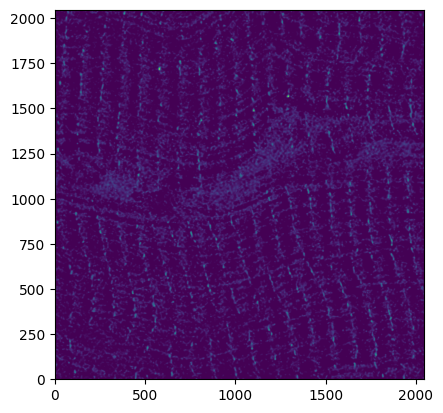

In [5]:
plt.imshow(np.max(data_full[1], axis=0), origin="lower")

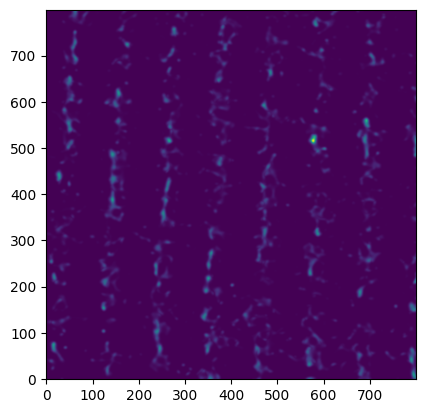

In [6]:
plt.imshow(np.max(data[1], axis=0), origin="lower")

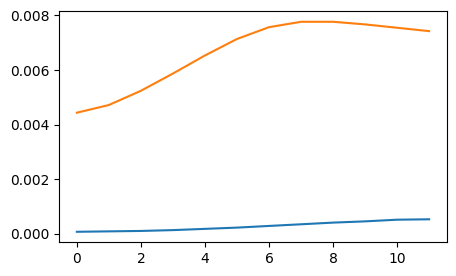

In [5]:
q = np.quantile(data, 0.7, axis=(-1, -2))
m = np.mean(data, axis=(-1, -2))

fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.plot(q[0])
ax.plot(m[0])

In [8]:
kernel_size = (data[0].shape[0] // 10, data[0].shape[1] // 5, data[0].shape[2] // 5)
data_equalized = [
    skimage.exposure.equalize_adapthist(d, kernel_size, np.percentile(d.flatten(), 99))
    for d in data
]

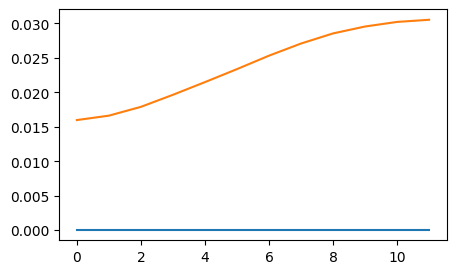

In [9]:
q = np.quantile(data_equalized, 0.7, axis=(-1, -2))
m = np.mean(data_equalized, axis=(-1, -2))

fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax.plot(q[0])
ax.plot(m[0])

In [10]:
data = data_equalized

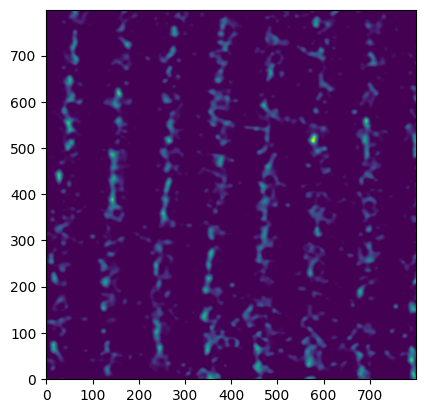

In [11]:
plt.imshow(np.mean(data_equalized[1][0:12], axis=0), origin="lower")

In [12]:
from tqdm import tqdm


# img_desmin, img_actinin = data[0], data[1]

img_desmin = skimage.transform.rescale(
    data_equalized[0][0:12], scale=pixel_sizes / np.min(pixel_sizes), order=1
)
img_actinin = skimage.transform.rescale(
    data_equalized[1][0:12], scale=pixel_sizes / np.min(pixel_sizes), order=1
)


def binarize_zstack(img):
    def binarize_z_slice(z_slice):
        bin = z_slice >= skimage.filters.threshold_otsu(z_slice)
        return skimage.morphology.binary_opening(bin, skimage.morphology.disk(3))

    return np.stack([binarize_z_slice(z_slice) for z_slice in tqdm(img)], axis=0)


desmin_segmented = rearrange(binarize_zstack(img_desmin), "z y x -> x y z")
actinin_segmented = rearrange(binarize_zstack(img_actinin), "z y x -> x y z")
# otsu = skimage.filters.threshold_otsu(img)
# actinin_segmented = skimage.filters.apply_hysteresis_threshold(img, 0.7 * otsu, otsu)


100%|██████████| 97/97 [00:04<00:00, 21.79it/s]


In [13]:
actinin_segmented = skimage.morphology.remove_small_objects(
    actinin_segmented, min_size=500
)
desmin_segmented = skimage.morphology.remove_small_objects(
    desmin_segmented, min_size=500
)

In [14]:
verts, faces, normals, values = skimage.measure.marching_cubes(
    actinin_segmented,
    level=0.5,
    spacing=np.ones_like(pixel_sizes) * np.min(pixel_sizes),
)
mesh_actinin = pv.PolyData.from_regular_faces(verts, faces)

verts, faces, normals, values = skimage.measure.marching_cubes(
    desmin_segmented,
    level=0.5,
    spacing=np.ones_like(pixel_sizes) * np.min(pixel_sizes),
)
mesh_desmin = pv.PolyData.from_regular_faces(verts, faces)

In [15]:
verts.shape

(1876617, 3)

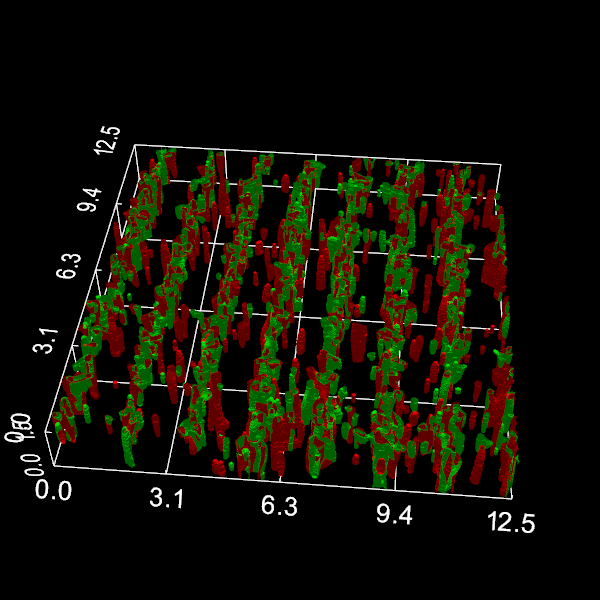

In [ ]:
mesh = pv.PolyData.from_regular_faces(verts, faces)

pl = pv.Plotter(notebook=True, window_size=(600, 600))
pl.add_mesh(
    mesh_desmin,
    color="#FF0000",
    show_scalar_bar=False,
)

pl.add_mesh(
    mesh_actinin,
    color="#00FF00",
    show_scalar_bar=False,
)
pl.set_background("black")
# pl.view_xy()
axis = pl.show_bounds(
    color="white",
    # bounds=[0.0, 8.0, 0.0, 8.0, 0.0, 2.0],
    grid="back",
    bold=False,
    font_size=20,
    location="outer",
    font_family="arial",
    padding=0.0,
    use_3d_text=False,
    n_zlabels=2,
    xtitle="",
    ytitle="",
    ztitle="",
    ticks="inside",
)
pl.camera.azimuth = 230
pl.camera.elevation = 10
# pl.camera.zoom(0.8)
pl.show()
# pl.save_graphic("../figures/fig_4/4d.svg")

In [17]:
mesh_desmin.save("../source_data/fig_4/4c_desmin.stl")
mesh_actinin.save("../source_data/fig_4/4c_actinin.stl")

In [18]:
skeleton_desmin = skimage.morphology.skeletonize(desmin_segmented)
skeleton_actinin = skimage.morphology.skeletonize(actinin_segmented)


In [19]:
skeleton_desmin = skimage.morphology.binary_dilation(
    skeleton_desmin, skimage.morphology.ball(radius=2)
)
skeleton_actinin = skimage.morphology.binary_dilation(
    skeleton_actinin, skimage.morphology.ball(radius=2)
)

In [20]:
def voxels_to_pyvista(
    voxels: np.ndarray, spacing: Sequence[float] | None = None, name: str = "scalars"
) -> pv.ImageData:
    if spacing is None:
        spacing = (1,) * voxels.ndim

    if len(spacing) != voxels.ndim:
        raise ValueError(
            "spacing must have length corresponding to the dimensionality of voxels."
        )
    grid = pv.ImageData(dimensions=[s + 1 for s in voxels.shape], spacing=spacing)
    grid.cell_data[name] = voxels.flatten(order="F")
    return grid


In [21]:
skeleton_actinin_voxels = voxels_to_pyvista(
    skeleton_actinin, np.ones_like(pixel_sizes) * np.min(pixel_sizes)
).threshold(0.5)
skeleton_desmin_voxels = voxels_to_pyvista(
    skeleton_desmin, np.ones_like(pixel_sizes) * np.min(pixel_sizes)
).threshold(0.5)

2026-07-08 22:08:28.397 ( 190.397s) [    14B785767740]vtkXOpenGLRenderWindow.:1416  WARN| bad X server connection. DISPLAY=


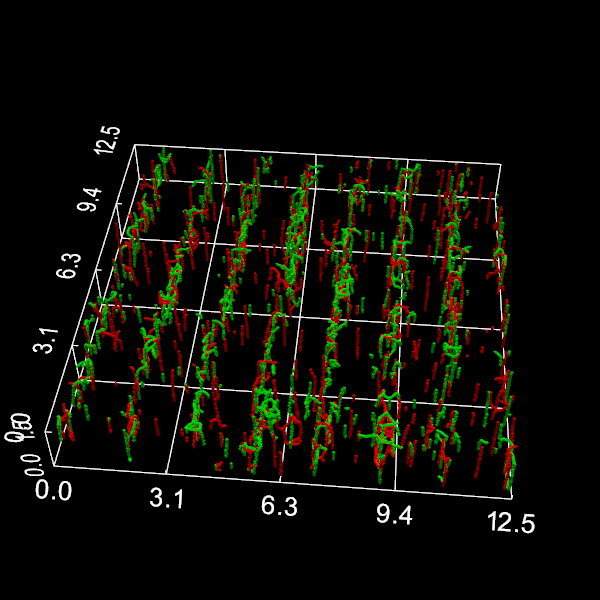

In [22]:
pl = pv.Plotter(notebook=True, window_size=(600, 600))
actor = pl.add_mesh(
    skeleton_desmin_voxels,
    cmap=["#FF0000"],
    show_scalar_bar=False,
)
actor = pl.add_mesh(
    skeleton_actinin_voxels,
    cmap=["#00FF00"],
    show_scalar_bar=False,
)
pl.set_background("black")
# pl.view_xy()
axis = pl.show_bounds(
    color="white",
    # bounds=[0.0, 8.0, 0.0, 8.0, 0.0, 2.0],
    grid="back",
    bold=False,
    font_size=20,
    location="outer",
    font_family="arial",
    padding=0.0,
    use_3d_text=False,
    n_zlabels=2,
    # show_zaxis=False,
    xtitle="",
    ytitle="",
    ztitle="",
    ticks="inside",
)
pl.camera.azimuth = 230
pl.camera.elevation = 10
# pl.camera.zoom(0.8)
pl.show()
# pl.save_graphic("../figures/fig_4/4e.svg")

In [24]:
skeleton_desmin_voxels.save("../source_data/fig_4/4d_desmin.pkl")
skeleton_actinin_voxels.save("../source_data/fig_4/4d_actinin.pkl")